In [1]:
import torch
import torchvision.transforms as transforms
import torch.nn as nn
import torch.nn.functional as F

import numpy as np
import matplotlib.pyplot as plt

from torchvision.datasets import CIFAR10
from torch.utils.data import DataLoader
from torch.optim import Adam
import torchvision

import random

# Set random seeds for reproducibility
seed = 1
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

# Ensure deterministic operations for reproducibility
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Determine the device to use (GPU if available, otherwise CPU)
device = 'cuda' if torch.cuda.is_available() else 'cpu'

## Data

In [2]:
# Define batch size for training and testing
batch_size = 256

# Define image transformations:
# ToTensor(): Converts a PIL Image or numpy.ndarray to a PyTorch Tensor. Also scales pixel values from [0, 255] to [0.0, 1.0].
# Normalize(): Normalizes a tensor image with mean and standard deviation.
# The values [0.4914, 0.4822, 0.4465] and [0.2470, 0.2435, 0.2616] are the mean and std deviation for CIFAR-10 dataset.
transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Normalize([0.4914, 0.4822, 0.4465],
                             [0.2470, 0.2435, 0.2616])
    ])

# Load the CIFAR-10 training dataset
train_set = CIFAR10(
    root='./data', # Directory to download data to
    train=True,    # Specifies training set
    download=True, # Download if not available
    transform=transform # Apply defined transformations
)

# Load the CIFAR-10 validation/test dataset
val_set = CIFAR10(
    root='./data',
    train=False,   # Specifies test set
    download=True,
    transform=transform
)

# Create DataLoader for the training set
trainloader = DataLoader(
    train_set,
    batch_size=batch_size, # Number of samples per batch
    shuffle=True,          # Shuffle data each epoch
    num_workers=4          # Number of subprocesses to use for data loading
)

# Create DataLoader for the test set
testloader = DataLoader(
    val_set,
    batch_size=batch_size,
    shuffle=False,         # No need to shuffle test data
    num_workers=4
)

100%|██████████| 170M/170M [00:05<00:00, 29.3MB/s]
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


In [ ]:
# Define batch size for training and testing
batch_size = 256

# Define image transformations:
# ToTensor(): Converts a PIL Image or numpy.ndarray to a PyTorch Tensor. Also scales pixel values from [0, 255] to [0.0, 1.0].
# Normalize(): Normalizes a tensor image with mean and standard deviation.
# The values [0.4914, 0.4822, 0.4465] and [0.2470, 0.2435, 0.2616] are the mean and std deviation for CIFAR-10 dataset.
transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Normalize([0.4914, 0.4822, 0.4465],
                             [0.2470, 0.2435, 0.2616])
    ])

# Load the CIFAR-10 training dataset
train_set = CIFAR10(
    root='./data', # Directory to download data to
    train=True,    # Specifies training set
    download=True, # Download if not available
    transform=transform # Apply defined transformations
)

# Load the CIFAR-10 validation/test dataset
val_set = CIFAR10(
    root='./data',
    train=False,   # Specifies test set
    download=True,
    transform=transform
)

# Create DataLoader for the training set
trainloader = DataLoader(
    train_set,
    batch_size=batch_size, # Number of samples per batch
    shuffle=True,          # Shuffle data each epoch
    num_workers=4          # Number of subprocesses to use for data loading
)

# Create DataLoader for the test set
testloader = DataLoader(
    val_set,
    batch_size=batch_size,
    shuffle=False,         # No need to shuffle test data
    num_workers=4
)

100%|██████████| 170M/170M [00:13<00:00, 12.9MB/s]
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


## Model

In [9]:
class CNNModel(nn.Module):
    def __init__(self, n_classes=10):
        super(CNNModel, self).__init__()
        # First convolutional block
        self.conv_layer1 = nn.Sequential(
            nn.Conv2d(3, 32, 3, stride=1, padding='same'), # Input channels=3 (RGB), Output channels=32, Kernel size=3, Same padding
            nn.ReLU() # Activation function
        )
        self.conv_layer2 = nn.Sequential(
            nn.Conv2d(32, 32, 3, stride=1, padding='same'),
            nn.ReLU(),
            nn.MaxPool2d(2, 2) # Max pooling layer with kernel size 2x2 and stride 2
        )

        # Second convolutional block
        self.conv_layer3 = nn.Sequential(
            nn.Conv2d(32, 64, 3, stride=1, padding='same'),
            nn.ReLU(),
        )
        self.conv_layer4 = nn.Sequential(
            nn.Conv2d(64, 64, 3, stride=1, padding='same'),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )

        # Third convolutional block
        self.conv_layer5 = nn.Sequential(
            nn.Conv2d(64, 128, 3, stride=1, padding='same'),
            nn.ReLU(),
        )
        self.conv_layer6 = nn.Sequential(
            nn.Conv2d(128, 128, 3, stride=1, padding='same'),
            nn.ReLU(),
        )
        self.conv_layer7 = nn.Sequential(
            nn.Conv2d(128, 128, 3, stride=1, padding='same'),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )

        # # Fourth convolutional block
        # self.conv_layer8 = nn.Sequential(
        #     nn.Conv2d(128, 256, 3, stride=1, padding='same'),
        #     nn.ReLU(),
        # )
        # self.conv_layer9 = nn.Sequential(
        #     nn.Conv2d(256, 256, 3, stride=1, padding='same'),
        #     nn.ReLU(),
        # )
        # self.conv_layer10 = nn.Sequential(
        #     nn.Conv2d(256, 256, 3, stride=1, padding='same'),
        #     nn.ReLU(),
        #     nn.MaxPool2d(2, 2)
        # )

        # Classifier block (fully connected layers)
        self.classifier = nn.Sequential(
            nn.Flatten(), # Flatten the 2D feature maps into a 1D vector
            nn.Linear(128*4*4, 256), # First linear layer: input features = 256*2*2 (from last MaxPool), output features = 512
            nn.ReLU(),
            nn.Linear(256, n_classes) # Second linear layer: output features = number of classes (e.g., 10 for CIFAR-10)
        )

    def forward(self, x):
        # Define the forward pass by chaining the convolutional and classifier layers
        x = self.conv_layer1(x)
        x = self.conv_layer2(x)
        x = self.conv_layer3(x)
        x = self.conv_layer4(x)
        x = self.conv_layer5(x)
        x = self.conv_layer6(x)
        x = self.conv_layer7(x)
        # x = self.conv_layer8(x)
        # x = self.conv_layer9(x)
        # x = self.conv_layer10(x)
        out = self.classifier(x)

        return out

In [10]:
# Instantiate the CNN model with 10 output classes (for CIFAR-10)
model = CNNModel(10)
# Move the model to the specified device (GPU or CPU)
model.to(device)
# Print the model architecture
print(model)

CNNModel(
  (conv_layer1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (1): ReLU()
  )
  (conv_layer2): Sequential(
    (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_layer3): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (1): ReLU()
  )
  (conv_layer4): Sequential(
    (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_layer5): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (1): ReLU()
  )
  (conv_layer6): Sequential(
    (0): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (1): ReLU()
  )
  (conv_layer7): Sequential(
    (0): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1)

# Train

In [11]:
# Define the loss function: Cross Entropy Loss is suitable for multi-class classification
criterion = nn.CrossEntropyLoss()
# Define the optimizer: Adam optimizer with a learning rate of 1e-3
optimizer = Adam(model.parameters(), lr=1e-3)

In [12]:
# Function to compute loss and accuracy for the test set
def evaluate(model, testloader, criterion):
    model.eval() # Set the model to evaluation mode
    test_loss = 0.0
    running_correct = 0
    total = 0
    with torch.no_grad(): # Disable gradient calculations during evaluation
        for images, labels in testloader:
            # Move inputs and labels to the device
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)
            test_loss += loss.item() # Accumulate batch loss

            # Get predictions
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0) # Total number of samples
            running_correct += (predicted == labels).sum().item() # Number of correct predictions

    accuracy = 100 * running_correct / total # Calculate accuracy
    test_loss = test_loss / len(testloader) # Calculate average test loss
    return test_loss, accuracy

In [13]:
# Lists to store training and testing metrics for plotting
train_losses = []
train_accuracies = []
test_losses = []
test_accuracies = []
# Maximum number of training epochs
max_epoch = 20

In [14]:
# Training loop
for epoch in range(max_epoch):
    model.train() # Set the model to training mode
    running_loss = 0.0
    running_correct = 0   # To track number of correct predictions
    total = 0             # To track total number of samples

    for i, (inputs, labels) in enumerate(trainloader, 0):
        # Move inputs and labels to the device
        inputs, labels = inputs.to(device), labels.to(device)

        # Zero the parameter gradients to prevent accumulation
        optimizer.zero_grad()

        # Forward pass: compute predicted outputs by passing inputs to the model
        outputs = model(inputs)
        # Compute the loss
        loss = criterion(outputs, labels)
        running_loss += loss.item() # Accumulate batch loss

        # Backward pass and optimization: compute gradients and update model parameters
        loss.backward()
        optimizer.step()

        # Determine class predictions and track accuracy
        _, predicted = torch.max(outputs.data, 1) # Get the index of the max log-probability
        total += labels.size(0) # Update total number of samples
        running_correct += (predicted == labels).sum().item() # Update number of correct predictions


    # Calculate epoch-wise training accuracy and loss
    epoch_accuracy = 100 * running_correct / total
    epoch_loss = running_loss / (i + 1)

    # Evaluate the model on the test set
    test_loss, test_accuracy = evaluate(model, testloader, criterion)
    # Print epoch statistics
    print(f"Epoch [{epoch + 1}/{max_epoch}], Loss: {epoch_loss:.4f}, Accuracy: {epoch_accuracy:.2f}%, Test Loss: {test_loss:.4f}, Test Accuracy: {test_accuracy:.2f}%")

    # Save metrics for plotting later
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)
    test_losses.append(test_loss)
    test_accuracies.append(test_accuracy)

Epoch [1/20], Loss: 1.7352, Accuracy: 35.50%, Test Loss: 1.4345, Test Accuracy: 47.43%
Epoch [2/20], Loss: 1.3015, Accuracy: 52.22%, Test Loss: 1.1632, Test Accuracy: 58.27%
Epoch [3/20], Loss: 1.0435, Accuracy: 62.48%, Test Loss: 0.9839, Test Accuracy: 64.76%
Epoch [4/20], Loss: 0.8685, Accuracy: 69.30%, Test Loss: 0.8556, Test Accuracy: 69.32%
Epoch [5/20], Loss: 0.7446, Accuracy: 73.61%, Test Loss: 0.7652, Test Accuracy: 72.88%
Epoch [6/20], Loss: 0.6621, Accuracy: 76.53%, Test Loss: 0.7564, Test Accuracy: 73.32%
Epoch [7/20], Loss: 0.5830, Accuracy: 79.57%, Test Loss: 0.7012, Test Accuracy: 75.59%
Epoch [8/20], Loss: 0.5053, Accuracy: 82.24%, Test Loss: 0.6699, Test Accuracy: 77.05%
Epoch [9/20], Loss: 0.4525, Accuracy: 84.04%, Test Loss: 0.7144, Test Accuracy: 75.33%
Epoch [10/20], Loss: 0.3846, Accuracy: 86.32%, Test Loss: 0.7042, Test Accuracy: 77.84%
Epoch [11/20], Loss: 0.3326, Accuracy: 88.10%, Test Loss: 0.7332, Test Accuracy: 77.76%
Epoch [12/20], Loss: 0.2721, Accuracy: 90

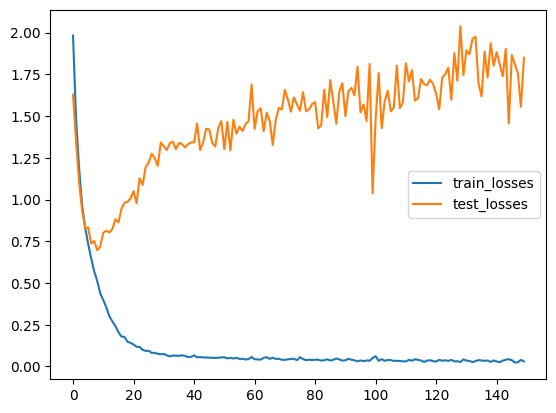

In [ ]:
import matplotlib.pyplot as plt

# Plotting training and test losses
plt.plot(train_losses, label='train_losses')
plt.plot(test_losses, label='test_losses')
plt.xlabel('Epoch') # Add x-axis label
plt.ylabel('Loss') # Add y-axis label
plt.title('Training and Test Loss over Epochs') # Add plot title
plt.legend() # Display legend
plt.show()

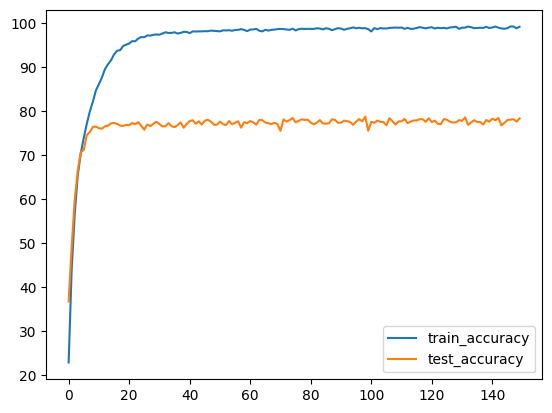

In [ ]:
import matplotlib.pyplot as plt

# Plotting training and test accuracies
plt.plot(train_accuracies, label='train_accuracy')
plt.plot(test_accuracies, label='test_accuracy')
plt.xlabel('Epoch') # Add x-axis label
plt.ylabel('Accuracy (%)') # Add y-axis label
plt.title('Training and Test Accuracy over Epochs') # Add plot title
plt.legend() # Display legend
plt.show()